Imports

In [2]:
# Importing necessary tools

import glob
import os

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (log_loss)
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io import shapereader
from shapely.geometry import Point

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["image.cmap"] = "coolwarm"

print("xarray", xr.__version__)



xarray 2025.6.1


Load and Prepare the Data

In [3]:
# Locating Data Files

DATA_DIR = "data:/data"

all_files = sorted(glob.glob(os.path.join(DATA_DIR, "*", "*.nc")))
print(f"Found {len(all_files)} files in {DATA_DIR}")
for f in all_files[:5]:
    print("  ", os.path.relpath(f, DATA_DIR))
print("   ...")

Found 60 files in data:/data
   2009_JanFeb/10m_u_component_of_wind_stream-oper_daily-mean.nc
   2009_JanFeb/10m_v_component_of_wind_0_daily-mean.nc
   2009_JanFeb/2m_temperature_0_daily-mean.nc
   2009_JanFeb/mean_sea_level_pressure_0_daily-mean.nc
   2009_JanFeb/total_precipitation_0_daily-mean.nc
   ...


Load Temperature Data (Creating Subset)

In [4]:
temp_files = sorted(glob.glob(os.path.join(DATA_DIR, "*", "*2m_temperature*nc")))

ds_temp = xr.open_mfdataset(temp_files, combine = "by_coords")
ds_temp

<xarray.Dataset> Size: 73MB
Dimensions:     (valid_time: 730, latitude: 105, longitude: 237)
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Data variables:
    t2m         (valid_time, latitude, longitude) float32 73MB dask.array<chunksize=(59, 105, 237), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-12-20T19:39 GRIB to CDM+CF via cfgrib-0.9.1...

Converting Temperature Units (c to F)

In [5]:
T2M = ds_temp["t2m"]
T2M

print ("Units: ", T2M.attrs.get("units"))
T2M_C = T2M - 273.15
T2M_F = (T2M_C * 9/5)+ 32
T2M_C.attrs["units"] = "degC"
T2M_F.attrs["units"] = "degF"
print ("Units: ", T2M_F.attrs.get("units"))

Units:  K
Units:  degF


Selecting Study Period

In [6]:
Temp_F = T2M_F.sel(valid_time = slice( "2009-01-01", "2010-12-31"))
display(Temp_F)

<xarray.DataArray 't2m' (valid_time: 730, latitude: 105, longitude: 237)> Size: 73MB
dask.array<add, shape=(730, 105, 237), dtype=float32, chunksize=(62, 105, 237), chunktype=numpy.ndarray>
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Attributes:
    units:    degF

Load Precipitation Data

In [7]:

precip_files = sorted(glob.glob(os.path.join(DATA_DIR, "*", "*total_precipitation*.nc")))

ds_precip = xr.open_mfdataset(precip_files, combine = "by_coords")
ds_precip

<xarray.Dataset> Size: 73MB
Dimensions:     (valid_time: 730, latitude: 105, longitude: 237)
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Data variables:
    tp          (valid_time, latitude, longitude) float32 73MB dask.array<chunksize=(59, 105, 237), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-12-20T19:43 GRIB to CDM+CF via cfgrib-0.9.1...

Convert Precipitation Units

In [8]:
P = ds_precip["tp"]
print(P.attrs.get("units"))

P_mm = P*1000
P_mm.attrs["units"] = "mm/day"
print(P_mm.attrs.get("units"))

m
mm/day


Selecting Study Period

In [9]:
# Seperating Precip into 2009 and 2010 
Precip = P_mm.sel(valid_time = slice("2009-01-01", "2010-12-31"))

display(Precip)



<xarray.DataArray 'tp' (valid_time: 730, latitude: 105, longitude: 237)> Size: 73MB
dask.array<mul, shape=(730, 105, 237), dtype=float32, chunksize=(62, 105, 237), chunktype=numpy.ndarray>
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Attributes:
    units:    mm/day

Define Study Region

In [10]:
# California Region
precipd_cali = Precip.sel(latitude= slice(42, 32.5), longitude= slice(-124, -114))

tempd_cali = Temp_F.sel(latitude=slice(42,32.5), longitude=slice(-124,-114))



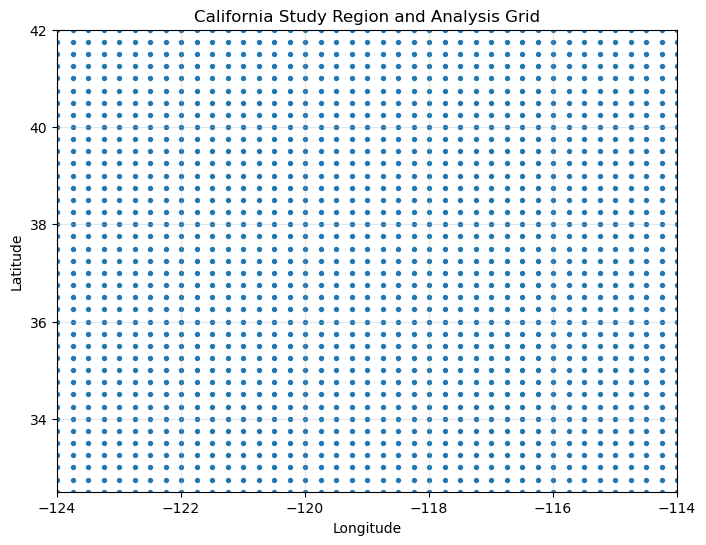

In [11]:
# Plot the study region and analysis grid

lon, lat = np.meshgrid(
    precipd_cali.longitude.values,
    precipd_cali.latitude.values
)

plt.figure(figsize=(8, 6))

plt.scatter(
    lon,
    lat,
    s=8
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("California Study Region and Analysis Grid")

plt.xlim(-124, -114)
plt.ylim(32.5, 42)

plt.grid(alpha=0.3)

plt.show()

Aggregate Data to Monthly Values
(Temperature is aggregated to monthly mean temperature, while precipitation is aggreagated to total monthly precipitation for each California grid cell)

In [12]:
# Aggregate daily data to monthly values
Temp_monthly =tempd_cali.resample(valid_time = "1MS").mean()
Precip_monthly = precipd_cali.resample(valid_time = "1MS").sum()

Temp_monthly= Temp_monthly.compute()
Precip_monthly = Precip_monthly.compute()
print(Temp_monthly.shape)
print(Precip_monthly.shape)


(24, 39, 41)
(24, 39, 41)


Define the Target

Relative Precipitation Deficit (RPD) occurs when precipitation in the current month is lower than the average of the previous three months. 

For each California Grid Cell: 
- 1 = RPD: current-month precipitation is below the previous three-month average
- 0 = No RPD: current-month precipitation is not below the previous three-month average

The RPD is the outcome that the logisitc model is designed to predict. 

In [13]:
# Calculate the precious three-month precipitation average
previous_3m_mean =(Precip_monthly.rolling(valid_time=3,min_periods=3).mean().shift(valid_time=1))


In [14]:
# Define RPD
target = (Precip_monthly < previous_3m_mean).astype(int)

In [15]:
# Remove the first 3 months because nont enough previous precip history to define RPD
target= target.isel(valid_time=slice(3,None))

Create Predictors

The predicotrs represent envuronmental conditions that were available before the month being predicted. 

In [16]:
#Model 1: Previous-month predictors
Temp_lag1 = Temp_monthly.shift(valid_time=1)
Precip_lag1 = Precip_monthly.shift(valid_time=1)

#Align predictors witht he target period
Temp_lag1 = Temp_lag1.isel(valid_time=slice(3,None))
Precip_lag1 = Precip_lag1.isel(valid_time = slice(3, None))

Additional Predictors for Model 2

Model 2 expands on Model 1 by including precipitation from the previous three months and the previous three-month precipitation average. 

In [17]:
Precip_lag2 = Precip_monthly.shift(valid_time=2)
Precip_lag3 = Precip_monthly.shift(valid_time=3)

Precip_lag2 = Precip_lag2.isel(valid_time=slice(3, None))
Precip_lag3 = Precip_lag3.isel(valid_time=slice(3, None))

previous_3m_mean = previous_3m_mean.isel(valid_time=slice(3, None))

Split the Data

The data are split chronologically to preserve the temporal structure of the problem. 

- Training: April-September 2009
- Validation: October-December 2009
- Test: January-December 2010

The Training data are used to fit the models, the validation data are used during model development, and the test data are held out for final evaluation. 

In [18]:
# Training: April–September 2009
Temp_train = Temp_lag1.sel(
    valid_time=slice("2009-04-01", "2009-09-01")
)

Precip_train = Precip_lag1.sel(
    valid_time=slice("2009-04-01", "2009-09-01")
)

y_train = target.sel(
    valid_time=slice("2009-04-01", "2009-09-01")
)


# Validation: October–December 2009
Temp_val = Temp_lag1.sel(
    valid_time=slice("2009-10-01", "2009-12-01")
)

Precip_val = Precip_lag1.sel(
    valid_time=slice("2009-10-01", "2009-12-01")
)

y_val = target.sel(
    valid_time=slice("2009-10-01", "2009-12-01")
)


# Test: January–December 2010
Temp_test = Temp_lag1.sel(
    valid_time=slice("2010-01-01", "2010-12-01")
)

Precip_test = Precip_lag1.sel(
    valid_time=slice("2010-01-01", "2010-12-01")
)

y_test = target.sel(
    valid_time=slice("2010-01-01", "2010-12-01")
)

In [19]:
# Reshape the data for scikit-learn

X_temp_train = Temp_train.values.reshape(-1, 1)
X_precip_train = Precip_train.values.reshape(-1, 1)
y_train_flat = y_train.values.reshape(-1)

X_temp_val = Temp_val.values.reshape(-1, 1)
X_precip_val = Precip_val.values.reshape(-1, 1)
y_val_flat = y_val.values.reshape(-1)

X_temp_test = Temp_test.values.reshape(-1, 1)
X_precip_test = Precip_test.values.reshape(-1, 1)
y_test_flat = y_test.values.reshape(-1)

X_train = np.column_stack((X_temp_train, X_precip_train))
X_val = np.column_stack((X_temp_val, X_precip_val))
X_test = np.column_stack((X_temp_test, X_precip_test))

print("Training:", X_train.shape, y_train_flat.shape)
print("Validation:", X_val.shape, y_val_flat.shape)
print("Test:", X_test.shape, y_test_flat.shape)

Training: (9594, 2) (9594,)
Validation: (4797, 2) (4797,)
Test: (19188, 2) (19188,)


In [20]:
#Checking our Training, Validation and Test data which tells us how many 0's and 1's we have. Sanity Check. 
print("Training class counts:", np.unique(y_train_flat, return_counts=True))
print("Validation class counts:", np.unique(y_val_flat, return_counts=True))
print("Test class counts:", np.unique(y_test_flat, return_counts=True))


Training class counts: (array([0, 1]), array([1731, 7863]))
Validation class counts: (array([0, 1]), array([3383, 1414]))
Test class counts: (array([0, 1]), array([ 9180, 10008]))


Model 1: Baseline Logistic Regression

Model 1 uses the previous month's temperature and precipitation to predict the probability of a relative precipitation deficit in the following month. 

In [21]:
# Making our Model
clf = LogisticRegression()

clf.fit(X_train,y_train_flat)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [22]:
y_val_prob = clf.predict_proba(X_val)[:, 1]

model_1_val_loss = log_loss(y_val_flat, y_val_prob)

print("Model 1 validation log loss:", model_1_val_loss)

Model 1 validation log loss: 1.2501814024078814


In [23]:
# Get probabilities for the 2010 test set
y_test_prob = clf.predict_proba(X_test)[:, 1]

model_1_test_loss = log_loss(y_test_flat, y_test_prob)
print("Model 1 test log loss:" ,model_1_test_loss)

Model 1 test log loss: 1.0504532546347218


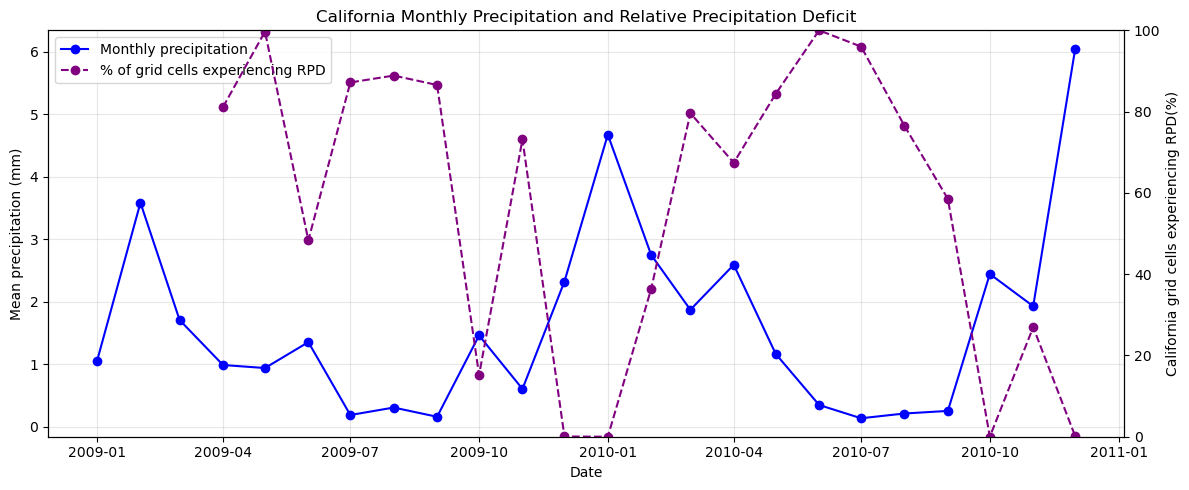

In [24]:
# California-wide mean monthly precipitation
precip_mean = Precip_monthly.mean(dim=["latitude", "longitude"])

# Percentage of California grid Cells experiencing RPD
target_percent = target.mean(dim=["latitude", "longitude"]) * 100

# Dates
precip_dates = precip_mean.valid_time.values
target_dates = target_percent.valid_time.values

fig, ax1 = plt.subplots(figsize=(12, 5))

# -------------------------
# Left axis: precipitation
# -------------------------
ax1.plot(
    precip_dates,
    precip_mean.values,
    marker="o",
    color = "blue",
    label="Monthly precipitation"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Mean precipitation (mm)")
ax1.grid(alpha=0.3)

# -------------------------
# Right axis: target %
# -------------------------
ax2 = ax1.twinx()

ax2.plot(
    target_dates,
    target_percent.values,
    marker="o",
    linestyle="--",
    color ="purple",
    label="% of grid cells experiencing RPD"
)

ax2.set_ylabel(
    "California grid cells experiencing RPD(%)"
)

ax2.set_ylim(0, 100)

# -------------------------
# Title
# -------------------------
plt.title(
    "California Monthly Precipitation and Relative Precipitation Deficit"
)

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left"
)

plt.tight_layout()
plt.show()

Model 2: Extended Precipitation History

Model 2 builds on the baseline model by including precipitation from the previous three months and the previous three-month mean precipitation. 

This allows the model to use a longer history of recent precipitation conditions when predicting the probability of RPD. 

Create Model 2 Predictor Matrices

In [25]:
X_train2 = np.column_stack([
    Temp_lag1.sel(valid_time=slice("2009-04-01", "2009-09-01")).values.reshape(-1),
    Precip_lag1.sel(valid_time=slice("2009-04-01", "2009-09-01")).values.reshape(-1),
    Precip_lag2.sel(valid_time=slice("2009-04-01", "2009-09-01")).values.reshape(-1),
    Precip_lag3.sel(valid_time=slice("2009-04-01", "2009-09-01")).values.reshape(-1),
    previous_3m_mean.sel(valid_time=slice("2009-04-01", "2009-09-01")).values.reshape(-1)
])

X_val2 = np.column_stack([
    Temp_lag1.sel(valid_time=slice("2009-10-01", "2009-12-01")).values.reshape(-1),
    Precip_lag1.sel(valid_time=slice("2009-10-01", "2009-12-01")).values.reshape(-1),
    Precip_lag2.sel(valid_time=slice("2009-10-01", "2009-12-01")).values.reshape(-1),
    Precip_lag3.sel(valid_time=slice("2009-10-01", "2009-12-01")).values.reshape(-1),
    previous_3m_mean.sel(valid_time=slice("2009-10-01", "2009-12-01")).values.reshape(-1)
])

X_test2 = np.column_stack([
    Temp_lag1.sel(valid_time=slice("2010-01-01", "2010-12-01")).values.reshape(-1),
    Precip_lag1.sel(valid_time=slice("2010-01-01", "2010-12-01")).values.reshape(-1),
    Precip_lag2.sel(valid_time=slice("2010-01-01", "2010-12-01")).values.reshape(-1),
    Precip_lag3.sel(valid_time=slice("2010-01-01", "2010-12-01")).values.reshape(-1),
    previous_3m_mean.sel(valid_time=slice("2010-01-01", "2010-12-01")).values.reshape(-1)
])

In [26]:
y_train2 = target.sel(
    valid_time=slice("2009-04-01", "2009-09-01")
).values.reshape(-1)

y_val2 = target.sel(
    valid_time=slice("2009-10-01", "2009-12-01")
).values.reshape(-1)

y_test2 = target.sel(
    valid_time=slice("2010-01-01", "2010-12-01")
).values.reshape(-1)

In [27]:
clf2= LogisticRegression(max_iter=1000)
clf2.fit(X_train2, y_train2)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [28]:
y_val2_prob = clf2.predict_proba(X_val2)[:,1]

In [29]:
val_log_loss2 = log_loss(y_val2,y_val2_prob)
print("Model 2 validation log loss:", val_log_loss2)

Model 2 validation log loss: 1.00391814121425


In [30]:
y_test2_prob = clf2.predict_proba(X_test2)[:, 1]

test_log_loss2 = log_loss(y_test2, y_test2_prob)


print("Model 2 test log loss:", test_log_loss2)


Model 2 test log loss: 0.7580821020648577


Graphs that compare two models

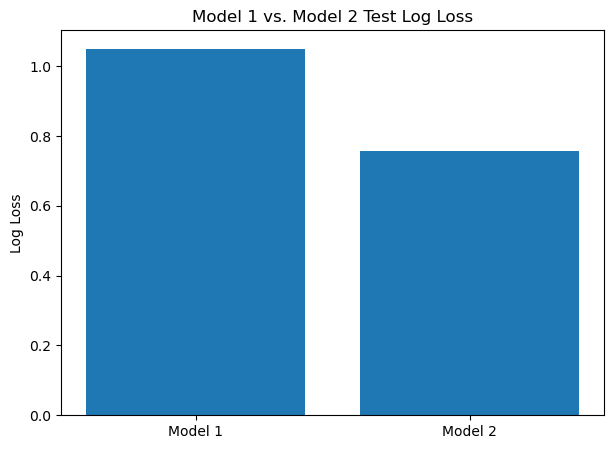

In [31]:
models = ["Model 1", "Model 2"]
log_losses = [
    model_1_test_loss,
    test_log_loss2
]

plt.figure(figsize=(7, 5))

plt.bar(models, log_losses)

plt.ylabel("Log Loss")
plt.title("Model 1 vs. Model 2 Test Log Loss")

plt.show()

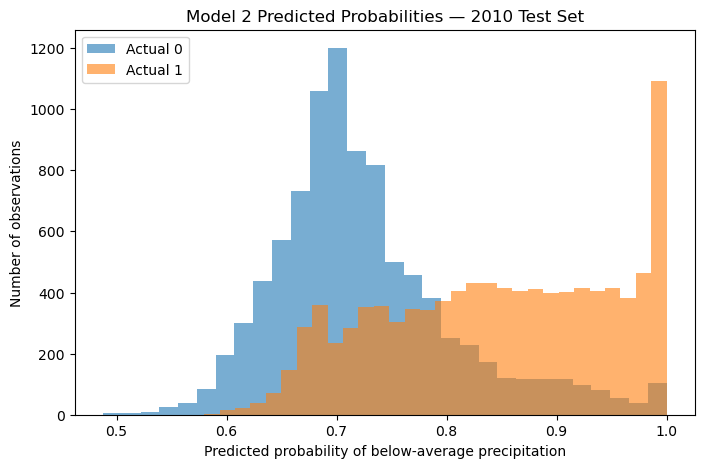

In [32]:
plt.figure(figsize=(8, 5))

plt.hist(
    y_test2_prob[y_test2 == 0],
    bins=30,
    alpha=0.6,
    label="Actual 0"
)

plt.hist(
    y_test2_prob[y_test2 == 1],
    bins=30,
    alpha=0.6,
    label="Actual 1"
)

plt.xlabel("Predicted probability of below-average precipitation")
plt.ylabel("Number of observations")
plt.title("Model 2 Predicted Probabilities — 2010 Test Set")
plt.legend()

plt.show()

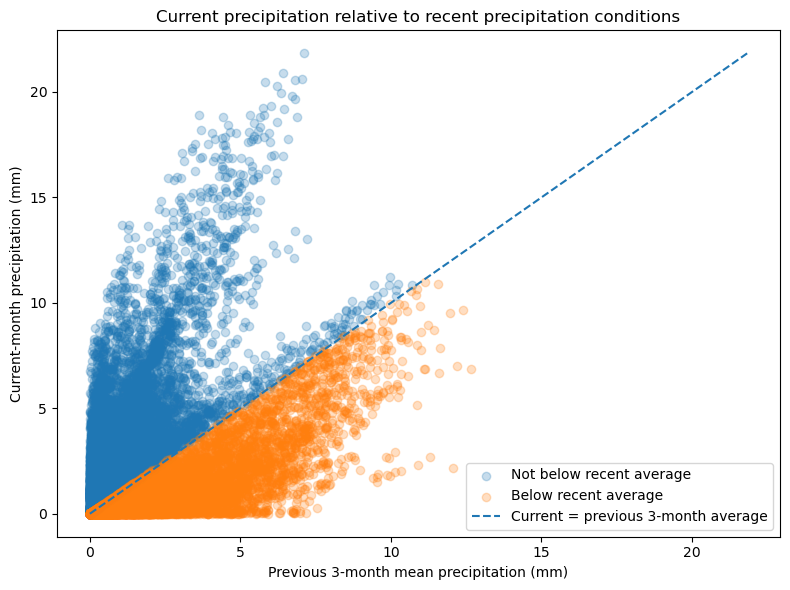

In [33]:
# Current-month precipitation, aligned with target
current_precip_plot = Precip_monthly.isel(
    valid_time=slice(3, None)
).values.reshape(-1)

# Previous 3-month average precipitation
previous_3m_plot = previous_3m_mean.values.reshape(-1)

# Target
target_plot = target.values.reshape(-1)

plt.figure(figsize=(8, 6))

plt.scatter(
    previous_3m_plot[target_plot == 0],
    current_precip_plot[target_plot == 0],
    alpha=0.25,
    label="Not below recent average"
)

plt.scatter(
    previous_3m_plot[target_plot == 1],
    current_precip_plot[target_plot == 1],
    alpha=0.25,
    label="Below recent average"
)

# 1:1 reference line
max_value = max(
    previous_3m_plot.max(),
    current_precip_plot.max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    label="Current = previous 3-month average"
)

plt.xlabel("Previous 3-month mean precipitation (mm)")
plt.ylabel("Current-month precipitation (mm)")
plt.title(
    "Current precipitation relative to recent precipitation conditions"
)

plt.legend()
plt.tight_layout()
plt.show()

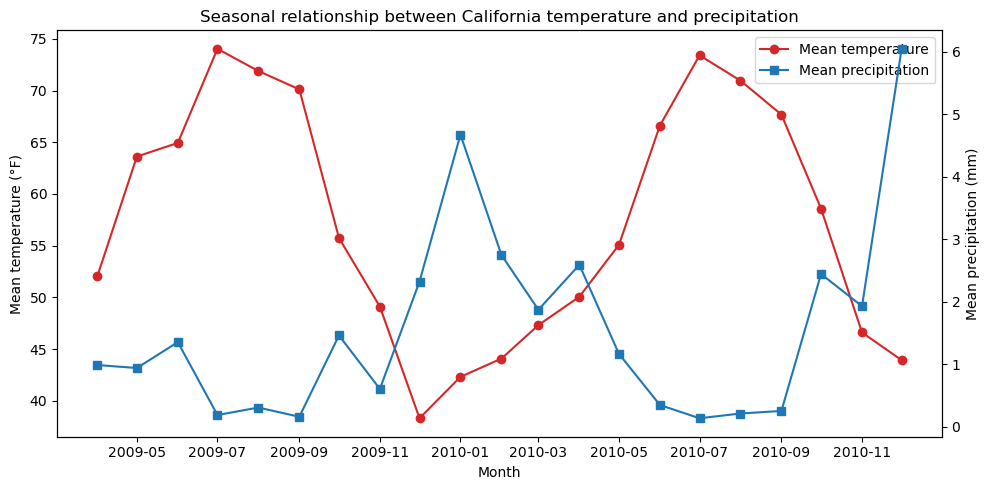

In [34]:
# California-wide monthly means
mean_temp = Temp_monthly.sel(
    valid_time=slice("2009-04-01", "2010-12-01")
).mean(dim=["latitude", "longitude"])

mean_precip = Precip_monthly.sel(
    valid_time=slice("2009-04-01", "2010-12-01")
).mean(dim=["latitude", "longitude"])

fig, ax1 = plt.subplots(figsize=(10, 5))

# Temperature
ax1.plot(
    mean_temp.valid_time,
    mean_temp,
    marker="o",
    color ="tab:red",
    label="Mean temperature"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Mean temperature (°F)")

# Precipitation
ax2 = ax1.twinx()

ax2.plot(
    mean_precip.valid_time,
    mean_precip,
    marker="s",
    label="Mean precipitation"
)

ax2.set_ylabel("Mean precipitation (mm)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper right"
)
plt.title("Seasonal relationship between California temperature and precipitation")

plt.tight_layout()

plt.show()

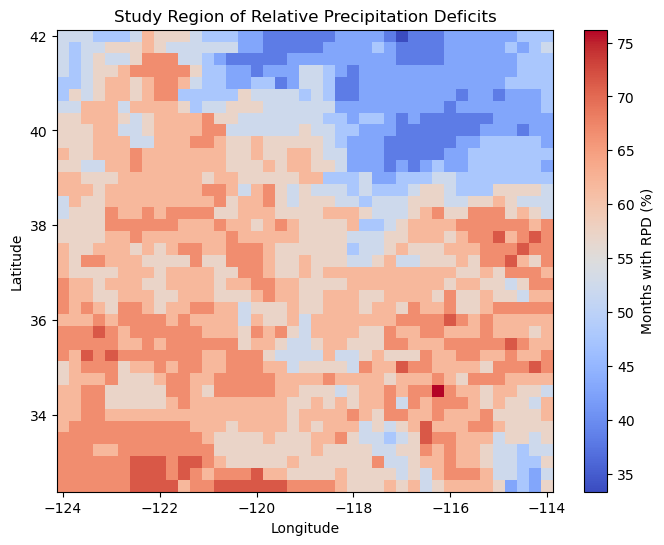

In [35]:
# Calculate the percentage of months each grid cell experienced RPD
rpd_frequency = target.mean(dim="valid_time") * 100

# Plot the spatial frequency of RPD
plt.figure(figsize=(8, 6))

rpd_frequency.plot(
    cmap="coolwarm",
    cbar_kwargs={"label": "Months with RPD (%)"}
)

plt.title("Study Region of Relative Precipitation Deficits")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

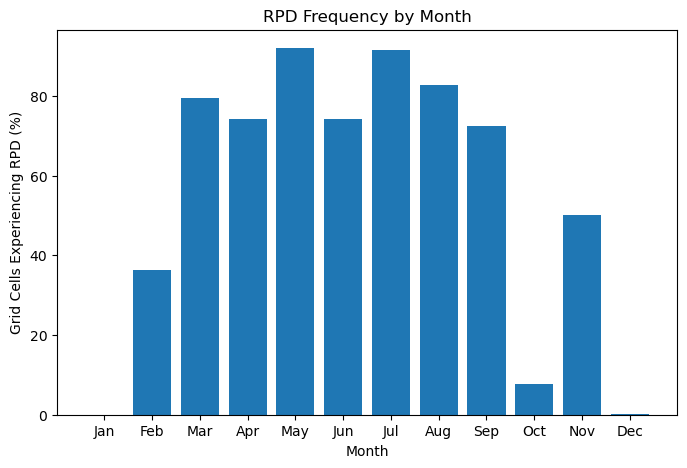

In [36]:
# Calculate the percentage of grid cells experiencing RPD for each month
rpd_by_month = (
    target
    .groupby("valid_time.month")
    .mean(dim=("valid_time", "latitude", "longitude"))
    * 100
)

# Plot monthly RPD frequency
plt.figure(figsize=(8, 5))

plt.bar(
    range(1, 13),
    rpd_by_month.values
)

plt.xlabel("Month")
plt.ylabel("Grid Cells Experiencing RPD (%)")
plt.title("RPD Frequency by Month")

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.show()

# Important note: there are a total of 1,599 grid cells in my area of study

Graph Showcasing Models Limitation

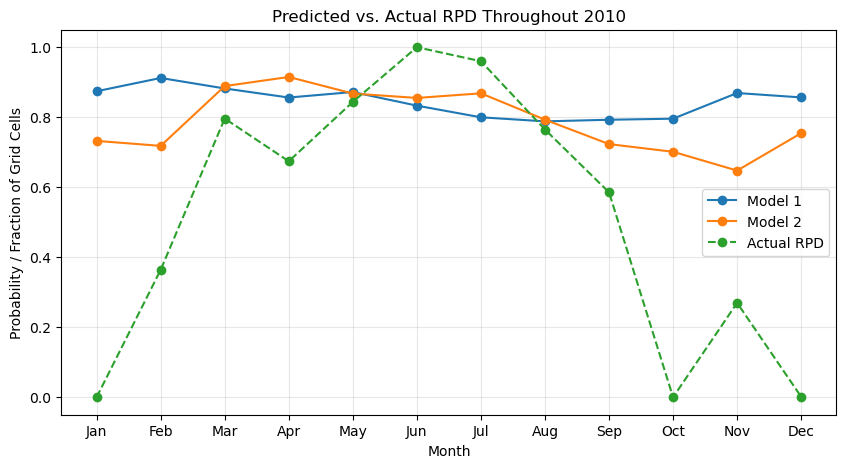

In [37]:
# Calculate monthly average predicted probabilities for 2010

model_1_prob_monthly = (
    y_test_prob.reshape(12, 39, 41)
    .mean(axis=(1, 2))
)

model_2_prob_monthly = (
    y_test2_prob.reshape(12, 39, 41)
    .mean(axis=(1, 2))
)

# Calculate the actual percentage of grid cells experiencing RPD each month
actual_rpd_monthly = (
    target
    .sel(valid_time=slice("2010-01-01", "2010-12-01"))
    .mean(dim=("latitude", "longitude"))
    .values
)

months = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Plot predictions and actual RPD frequency
plt.figure(figsize=(10, 5))

plt.plot(
    months,
    model_1_prob_monthly,
    marker="o",
    label="Model 1"
)

plt.plot(
    months,
    model_2_prob_monthly,
    marker="o",
    label="Model 2"
)

plt.plot(
    months,
    actual_rpd_monthly,
    marker="o",
    linestyle="--",
    label="Actual RPD"
)

plt.xlabel("Month")
plt.ylabel("Probability / Fraction of Grid Cells")
plt.title("Predicted vs. Actual RPD Throughout 2010")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Visualization of my Area of Study only

In [38]:
# Create the full analysis grid
lon, lat = np.meshgrid(
    precipd_cali.longitude.values,
    precipd_cali.latitude.values
)

# Get state boundaries
shapefile = shapereader.natural_earth(
    resolution="10m",
    category="cultural",
    name="admin_1_states_provinces"
)

reader = shapereader.Reader(shapefile)

# Find California
california = None

for record in reader.records():
    if record.attributes["name"] == "California":
        california = record.geometry
        break

# Create a visualization-only mask
california_mask = np.array([
    california.contains(Point(x, y))
    for x, y in zip(lon.ravel(), lat.ravel())
]).reshape(lon.shape)

/Users/jesse/miniforge3/envs/290A/lib/python3.10/site-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_1_states_provinces.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


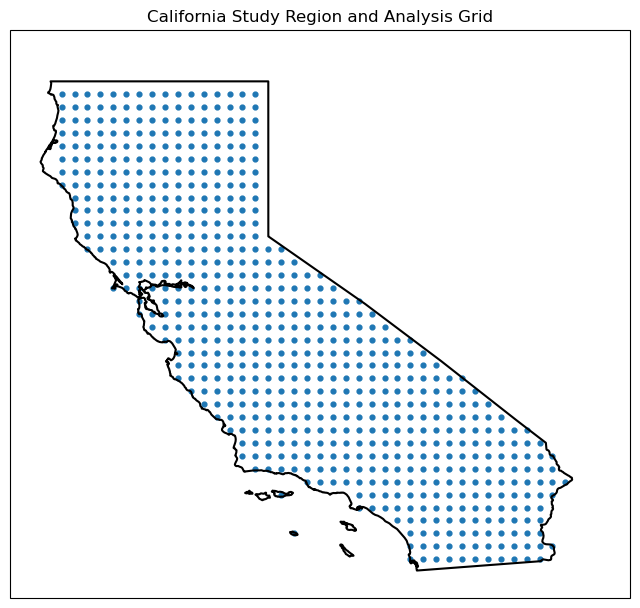

In [39]:
# Plot the California-shaped analysis grid

fig = plt.figure(figsize=(8, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

# Plot only grid points inside California
ax.scatter(
    lon[california_mask],
    lat[california_mask],
    s=12,
    transform=ccrs.PlateCarree()
)

# Add California boundary
ax.add_geometries(
    [california],
    crs=ccrs.PlateCarree(),
    facecolor="none",
    edgecolor="black",
    linewidth=1.5
)

ax.set_extent([-125, -113, 32, 43])

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("California Study Region and Analysis Grid")

plt.show()